# Connecting Python to PostgreSQL and visualizing CO2 emissions.

## Libraries and their purpose:
## psycopg - connects Python to PostgreSQL.
## python-dotenv - loads configuration variables from a local .env file.
## pandas - stores query results in DataFrames and support data analysis.
## matplotlib - creates visualizations of the extracted data.

In [1]:
from dotenv import load_dotenv
import psycopg
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
load_dotenv(override = True)

True

In [3]:
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")
dbname = os.getenv("DB_NAME")
user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")

### Connecting with PostgreSQL

In [4]:
conn = psycopg.connect(host=host, port=port, dbname=dbname, user=user, password=password)

### Creating cursor object to execute commands in PostgreSQL

In [5]:
cur = conn.cursor()

In [6]:
cur.execute("SELECT country, year, co2, co2_per_capita FROM co2")
rows = cur.fetchall()
len(rows)

70

In [7]:
df_co2_percap = pd.DataFrame(rows, columns=["country", "year", "co2", "co2_per_capita"])

In [8]:
df_co2_percap["country"].unique()

array(['European Union (27)', 'Poland'], dtype=object)

In [9]:
df_poland = df_co2_percap[df_co2_percap["country"] == "Poland"]
df_eu = df_co2_percap[df_co2_percap["country"] == "European Union (27)"]

## Creating visualizations

## 1. Analysing total CO2 emissions, CO2 emissions per capita, and their percentage changes in Poland and the EU-27 from 1990 until 2024 to show how CO2 emissions changed over time

### CO2 Emissions per Capita: Poland vs EU-27 (1990-2024)

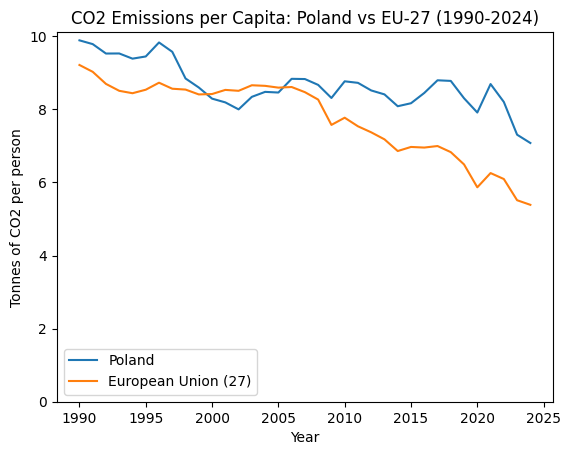

In [10]:
xplot_PL = df_poland["year"]
xplot_EU = df_eu["year"]
yplot_PL = df_poland["co2_per_capita"]
yplot_EU = df_eu["co2_per_capita"]

plt.title("CO2 Emissions per Capita: Poland vs EU-27 (1990-2024)")
plt.xlabel("Year")
plt.ylabel("Tonnes of CO2 per person")

plt.plot(xplot_PL, yplot_PL, label = "Poland")
plt.plot(xplot_EU, yplot_EU, label = "European Union (27)")
plt.legend()
plt.ylim(bottom=0)
plt.show()

## From 1990 to 2024, both series show a clear downward trend in CO₂ emissions per capita, with more pronounced year-to-year fluctuations in Poland. Throughout the period, Poland's emissions per capita remained higher than the EU-27 average.

### Percentage change in CO₂ Emissions per Capita (1990–2024)

In [11]:
cur.execute("""SELECT
country,
co2_1990,
co2_2024,
round(((co2_2024 - co2_1990) / co2_1990) * 100,2) as percentage_change
FROM
(
SELECT
country,
max(CASE WHEN YEAR = 1990 THEN co2_per_capita end) as co2_1990,
max(CASE WHEN YEAR = 2024 THEN co2_per_capita end) as co2_2024
FROM co2
group by country
) as emissions;""")
rows2 = cur.fetchall()

In [12]:
df_co2_per_change = pd.DataFrame(rows2, columns=["country", "co2_1990", "co2_2024", "percentage_change"])

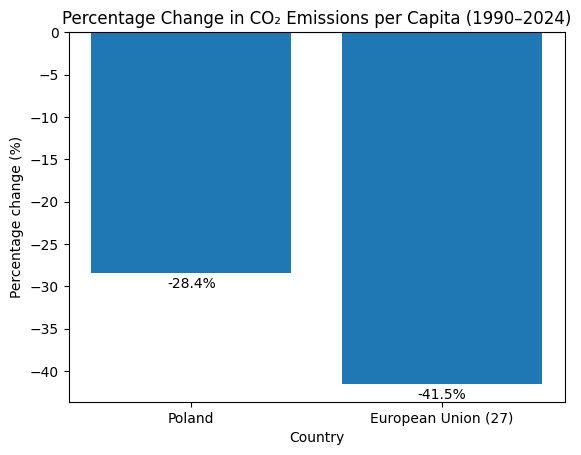

In [13]:
xplot_co2_per_capita_change = df_co2_per_change["country"]
yplot_co2_per_capita_change = df_co2_per_change["percentage_change"]

plt.title("Percentage Change in CO₂ Emissions per Capita (1990–2024)")
plt.xlabel("Country")
plt.ylabel("Percentage change (%)")
plt.axhline(y=0)

bars_co2pc = plt.bar(xplot_co2_per_capita_change, yplot_co2_per_capita_change)
plt.bar_label(bars_co2pc, fmt="%.1f%%", padding = 3)
plt.show()


### Total CO2 emissions: Poland vs EU-27 (1990-2024)

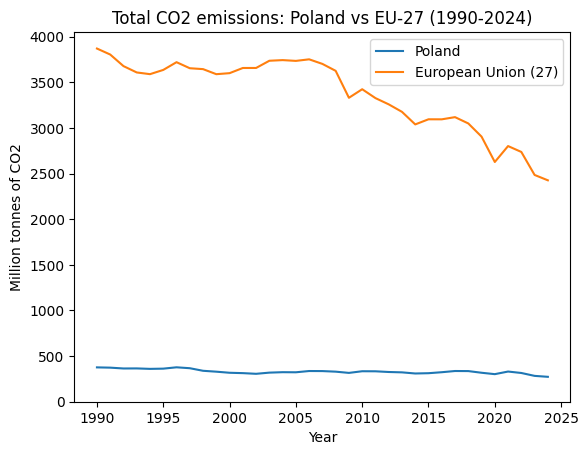

In [14]:
xplot_PL = df_poland["year"]
xplot_EU = df_eu["year"]
yplot2_PL = df_poland["co2"]
yplot2_EU = df_eu["co2"]

plt.title("Total CO2 emissions: Poland vs EU-27 (1990-2024)")
plt.xlabel("Year")
plt.ylabel("Million tonnes of CO2")

plt.plot(xplot_PL, yplot2_PL, label = "Poland")
plt.plot(xplot_EU, yplot2_EU, label = "European Union (27)")
plt.legend()
plt.ylim(bottom=0)
plt.show()

### Percentage change in CO₂ Emissions (1990–2024)

In [15]:
cur.execute("""SELECT
country,
co2_1990,
co2_2024,
round(((co2_2024 - co2_1990) / co2_1990) * 100,2) as percentage_change
FROM
(
SELECT
country,
max(CASE WHEN YEAR = 1990 THEN co2 end) as co2_1990,
max(CASE WHEN YEAR = 2024 THEN co2 end) as co2_2024
FROM co2
group by country
) as emissions;""")
rows3 = cur.fetchall()

In [16]:
df_co2_total_change = pd.DataFrame(
    rows3,
    columns=["country", "co2_1990", "co2_2024", "percentage_change"]
)

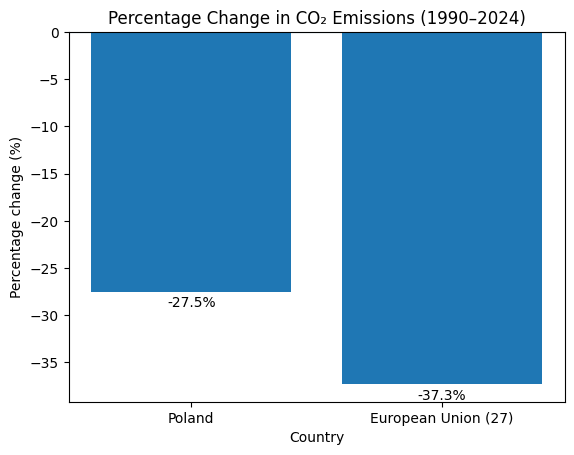

In [17]:
xplot_co2_change = df_co2_total_change["country"]
yplot_co2_change = df_co2_total_change["percentage_change"]

plt.title("Percentage Change in CO₂ Emissions (1990–2024)")
plt.xlabel("Country")
plt.ylabel("Percentage change (%)")
plt.axhline(y=0)

bars_co2 = plt.bar(xplot_co2_change, yplot_co2_change)
plt.bar_label(bars_co2, fmt="%.1f%%", padding = 3)
plt.show()

## CO2 emissions per capita decreased over time in both Poland (by 28.4%) and the EU-27 (by 41.5%). A year-by-year analysis reveals some fluctuations between 2002 and 2022, which are particularly noticeable in Poland.

## Total CO2 emissions also decreased in both Poland (by 27.5%) and the EU-27 (by 37.3%), representing a significant reduction.

## 2. Analysing household electricity price trends in Poland and the EU-27 from 2007 to 2024

The selected electricity price series uses the following filters:

- **Geography:** Poland (`PL`) and European Union (`EU27_2020`)
- **Consumption band:** `KWH2500-4999`
- **Taxes and levies:** All taxes and levies included (`I_TAX`)
- **Currency:** Euro (`EUR`)
 
Note: The Polish electricity price series has a missing observation for 2007-S1. The annual price for 2007 is therefore calculated using the available semi-annual observation(s)

## Electricity price per household in Poland and EU-27 (2007-2024)

In [18]:
cur.execute("""SELECT 
country,
year,
electricity_price
FROM 
electricity_price
ORDER BY
country, year;""")

ep1 = cur.fetchall()

In [19]:
df_ep = pd.DataFrame(ep1, columns=["country", "year", "electricity_price"])

In [20]:
df_ep_PL = df_ep[df_ep["country"] == "Poland"]
df_ep_EU = df_ep[df_ep["country"] == "European Union (27)"]

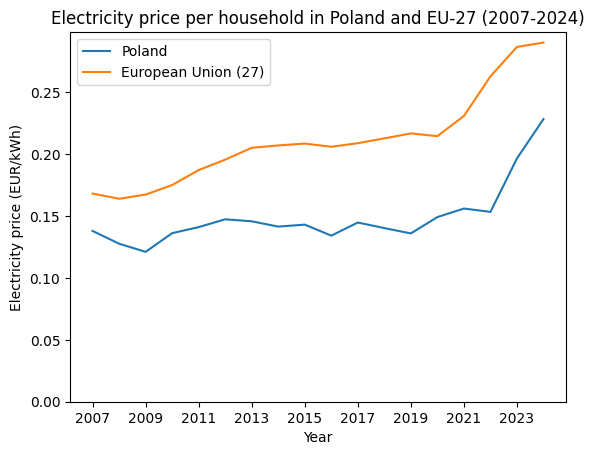

In [21]:
xplot_PLep = df_ep_PL["year"]
xplot_EUep = df_ep_EU["year"]
yplot_PLep = df_ep_PL["electricity_price"]
yplot_EUep = df_ep_EU["electricity_price"]

plt.title("Electricity price per household in Poland and EU-27 (2007-2024)")
plt.xlabel("Year")
plt.ylabel("Electricity price (EUR/kWh)")


plt.plot(xplot_PLep, yplot_PLep, label = "Poland")
plt.plot(xplot_EUep, yplot_EUep, label = "European Union (27)")
plt.legend()
plt.ylim(bottom =0)

year_interval = range(2007,2025,2)
plt.xticks(year_interval)

plt.show()

## Percentage change in electricity price between 2007 and 2024

In [22]:
cur.execute("""SELECT
country,
electricity_price_2007,
electricity_price_2024,
round(((electricity_price_2024 - electricity_price_2007) / electricity_price_2007) * 100,2) as percentage_change
FROM
(
SELECT
country,
max(CASE WHEN year = 2007 THEN electricity_price END) as electricity_price_2007,
max(CASE WHEN year = 2024 THEN electricity_price END) as electricity_price_2024
FROM
electricity_price
GROUP BY
country
) as electricity_prices;""")

ep2 = cur.fetchall()


In [23]:
df_ep_per_change = pd.DataFrame(
ep2, columns=["country", "electricity_price_2007", "electricity_price_2024", "percentage_change"])

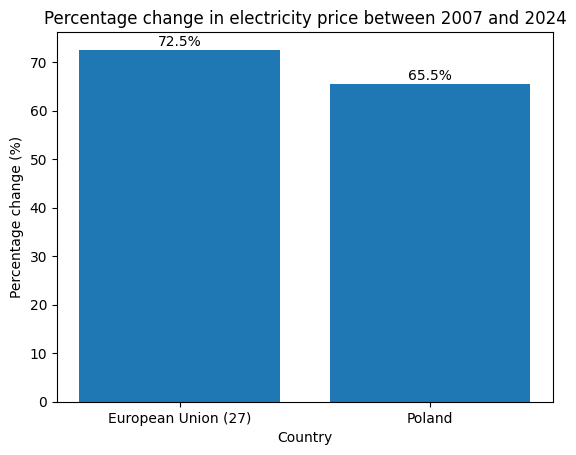

In [24]:
xplot_ep_per_change = df_ep_per_change["country"]
yplot_ep_per_change = df_ep_per_change["percentage_change"]

plt.title("Percentage change in electricity price between 2007 and 2024")
plt.xlabel("Country")
plt.ylabel("Percentage change (%)")

bars_ep = plt.bar(xplot_ep_per_change, yplot_ep_per_change)
plt.bar_label(bars_ep, fmt="%.1f%%", padding = 1)
plt.show()


## Household electricity prices increased significantly between 2007 and 2024, rising by 65.5% in Poland and 72.5% in EU-27. The sharpest increase occurred around 2022.

## 3. Analysing annual net earnings trends in Poland and the EU-27 from 2013 to 2024.

The selected wages series uses:

- **Geography:** Poland (PL) and European Union (`EU27_2020`)
- **Earnings case:** single person without children earning 100% of the average (`P1_NCH_AW100`)
- **Earnings structure:** Net earning (`NET`)
- **Currency:** Euro (`EUR`)

## Annual net earnings in Poland and EU-27 (2013-2024)

In [25]:
cur.execute("""SELECT
country,
year,
annual_net_earnings
FROM wages
ORDER BY country, year;""")

wg = cur.fetchall()

In [26]:
df_wg = pd.DataFrame(wg, columns = ["country", "year", "annual_net_earnings"])

df_PLwg = df_wg[df_wg["country"] == "Poland"]
df_EUwg = df_wg[df_wg["country"] == "European Union (27)"]

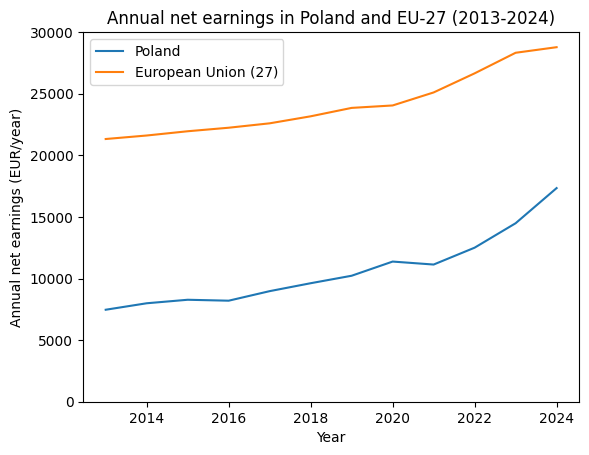

In [27]:
xplot_PLwg = df_PLwg["year"]
xplot_EUwg = df_EUwg["year"]
yplot_PLwg = df_PLwg["annual_net_earnings"]
yplot_EUwg = df_EUwg["annual_net_earnings"]

plt.title("Annual net earnings in Poland and EU-27 (2013-2024)")
plt.xlabel("Year")
plt.ylabel("Annual net earnings (EUR/year)")
plt.ylim(bottom = 0)

net_earnings_interval = range(0, 35000, 5000)
plt.yticks(net_earnings_interval)

plt.plot(xplot_PLwg, yplot_PLwg, label = "Poland")
plt.plot(xplot_EUwg, yplot_EUwg, label = "European Union (27)")
plt.legend()

plt.show()

## Percentage change in annual net earnings between 2013 and 2024

In [28]:
cur.execute("""SELECT
country,
wages_2013,
wages_2024,
round(((wages_2024 - wages_2013) / wages_2013) * 100,2) as percentage_change
FROM
(
SELECT
country,
max(CASE WHEN year = 2013 THEN annual_net_earnings end) as wages_2013,
max(CASE WHEN year = 2024 THEN annual_net_earnings end) as wages_2024
FROM wages
GROUP BY country
) as wages;""")

wg_per_change = cur.fetchall()

In [29]:
df_wg_per_change = pd.DataFrame(
    wg_per_change, columns=["country", "wages_2013", "wages_2024", "percentage_change"]
)

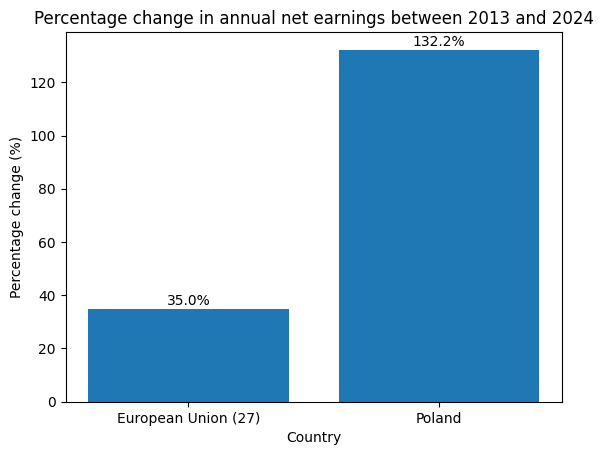

In [30]:
xplot_wg_per_change = df_wg_per_change["country"] 
yplot_wg_per_change = df_wg_per_change["percentage_change"] 

plt.title("Percentage change in annual net earnings between 2013 and 2024")

plt.xlabel("Country")
plt.ylabel("Percentage change (%)")

bars_wg_per_change = plt.bar(xplot_wg_per_change, yplot_wg_per_change)
plt.bar_label(bars_wg_per_change, fmt="%.1f%%", padding = 1)
plt.show()

## Annual net earnings increased in both the EU-27 and Poland. In Poland, annual net earnings rose much more significantly (by 132.2%) than in the EU-27 (by 35%).

## 4. Analysing electricity affordability trends in Poland and the EU-27 between 2013 and 2024.

## Electricity Affordability: Poland vs EU-27 (2013–2024)

In [31]:
cur.execute("""SELECT
a.country,
a.year,
a.annual_net_earnings,
b.electricity_price,
(a.annual_net_earnings / b.electricity_price) as affordability_index
FROM 
wages a
INNER JOIN
electricity_price b
ON 
a.country = b.country
AND
a.year = b.year
ORDER BY
country, year;""")

aff = cur.fetchall()

In [32]:
df_aff = pd.DataFrame(
    aff, columns = ["country", "year", "annual_net_earnings", "electricity_price", "affordability_index"]
)

df_PLaff = df_aff[df_aff["country"] == "Poland"]
df_EUaff = df_aff[df_aff["country"] == "European Union (27)"]                

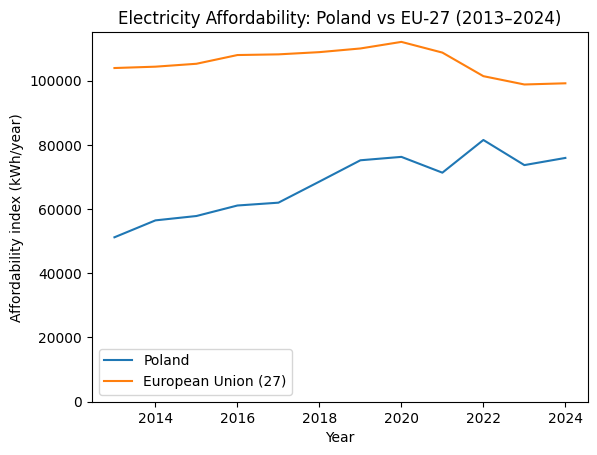

In [33]:
xplot_PLaff = df_PLaff["year"]
xplot_EUaff = df_EUaff["year"]
yplot_PLaff = df_PLaff["affordability_index"]
yplot_EUaff = df_EUaff["affordability_index"]

plt.title("Electricity Affordability: Poland vs EU-27 (2013–2024)")
plt.xlabel("Year")
plt.ylabel("Affordability index (kWh/year)")

plt.plot(xplot_PLaff, yplot_PLaff, label = "Poland")
plt.plot(xplot_EUaff, yplot_EUaff, label = "European Union (27)")

plt.ylim(bottom = 0)
plt.legend()

plt.show()

## Percentage change of affordability index between 2013 and 2024

In [34]:
cur.execute("""SELECT
country,
affordability_index_2013,
affordability_index_2024,
ROUND(
((affordability_index_2024 - affordability_index_2013) 
/ affordability_index_2013) * 100,2
) as percentage_change
FROM
(
SELECT
country,
MAX(CASE WHEN year = 2013 THEN affordability_index end) as affordability_index_2013,
MAX(CASE WHEN year = 2024 THEN affordability_index end) as affordability_index_2024
FROM
(
SELECT
a.country,
a.annual_net_earnings,
a.year,
b.electricity_price,
(a.annual_net_earnings / b.electricity_price) as affordability_index
FROM 
wages a
INNER JOIN
electricity_price b
ON 
a.country = b.country
AND
a.year = b.year
) 
as affordability_index_change
GROUP BY country
) AS Affordability_index_percentage_change;""")

aff_per_change = cur.fetchall()

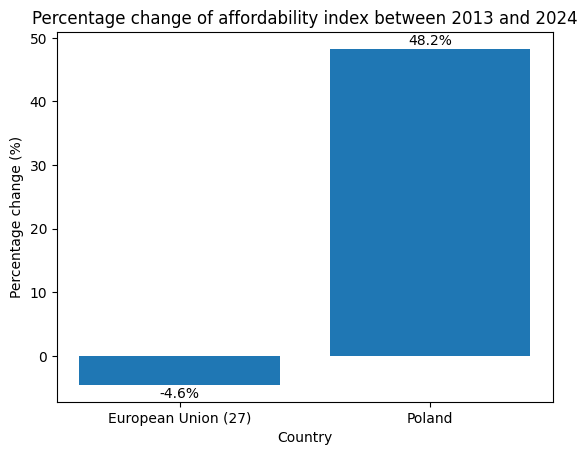

In [37]:
df_aff_per_change = pd.DataFrame(
    aff_per_change, columns = ["country", "affordability_index_2013", "affordability_index_2024", 
                               "percentage_change"]
)

plt.title("Percentage change of affordability index between 2013 and 2024")
plt.xlabel("Country")
plt.ylabel("Percentage change (%)")

xplot_aff_per_change = df_aff_per_change["country"]
yplot_aff_per_change = df_aff_per_change["percentage_change"]

bar_aff_per_change = plt.bar(xplot_aff_per_change, yplot_aff_per_change)
plt.bar_label(bar_aff_per_change, fmt = "%.1f%%", padding = 1)

plt.show()

## The affordability index remained relatively stable in the EU-27 until around 2020, after which it declined before stabilising around 2022. In Poland, the index showed an overall upward trend, despite some fluctuations between 2020 and 2023.

## Between 2013 and 2024, the index decreased by 4.6% in the EU-27, while it increased by 48.2% in Poland. This means that the selected modelled annual net earnings could purchase fewer kWh of electricity in the EU-27 and more in Poland in 2024 than in 2013. The index is based on a specific modelled earnings case and selected household electricity prices, so it should not be interpreted as a measure of affordability for every household.

### Closing connection with PostgreSQL

In [38]:
cur.close()
conn.close()